In [1]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18

# 1. Set Reproducibility Seeds (Required for GitHub repo & Report)
SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# 2. Device Configuration (Uses Colab/Kaggle T4 GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 3. Experiment Configuration
# Choose "MNIST" (fast, directly reproduces Section 3 'mythical digit 3' experiment)
# or "CIFAR10" (also supported out-of-the-box with zero errors)
DATASET_NAME = "MNIST"
BATCH_SIZE = 128
NUM_CLASSES = 10

Using device: cuda


In [2]:
if DATASET_NAME == "MNIST":
    IN_CHANNELS = 1
    transform_train = transforms.Compose([
        transforms.RandomCrop(28, padding=2), # Paper Section 3: jittered by up to 2 pixels
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])
    transform_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])
    train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_train)
    test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_test)

elif DATASET_NAME == "CIFAR10":
    IN_CHANNELS = 3
    transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])
    transform_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])
    train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
    test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

# Standard DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# --- Held-Out Class Setup (Omitting Class 3 as in Section 3 of the Paper) ---
HELD_OUT_CLASS = 3

train_targets = np.array(train_dataset.targets)
test_targets = np.array(test_dataset.targets)

# Indices without class 3 for training the student
train_no_3_idx = np.where(train_targets != HELD_OUT_CLASS)[0]
# Indices of ONLY class 3 in the test set
test_only_3_idx = np.where(test_targets == HELD_OUT_CLASS)[0]

train_no_3_loader = DataLoader(Subset(train_dataset, train_no_3_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_only_3_loader = DataLoader(Subset(test_dataset, test_only_3_idx), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Dataset: {DATASET_NAME} | Full Train Samples: {len(train_dataset)} | Test Samples: {len(test_dataset)}")
print(f"Transfer Set (No Class {HELD_OUT_CLASS}): {len(train_no_3_idx)} samples | Test Class {HELD_OUT_CLASS} Samples: {len(test_only_3_idx)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 506kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.51MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.86MB/s]

Dataset: MNIST | Full Train Samples: 60000 | Test Samples: 10000
Transfer Set (No Class 3): 53869 samples | Test Class 3 Samples: 1010



/tmp/ipykernel_613/887949855.py:37: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  train_targets = np.array(train_dataset.targets)
/tmp/ipykernel_613/887949855.py:38: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  test_targets = np.array(test_dataset.targets)


In [3]:
def get_teacher_resnet(in_channels=1, num_classes=10):
    """Creates a ResNet-18 Teacher adapted for 28x28 (MNIST) or 32x32 (CIFAR-10) images."""
    model = resnet18(weights=None, num_classes=num_classes)
    # Replace 7x7 stride-2 conv and maxpool with 3x3 stride-1 conv for small images
    model.conv1 = nn.Conv2d(in_channels, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    return model

class SmallStudentCNN(nn.Module):
    """A lightweight Student CNN with ~100x fewer parameters than ResNet-18."""
    def __init__(self, in_channels=1, num_classes=10):
        super(SmallStudentCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((4, 4)) # Guarantees 32*4*4 = 512 features for both MNIST & CIFAR-10
        )
        self.classifier = nn.Sequential(
            nn.Linear(32 * 4 * 4, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        logits = self.classifier(x)
        return logits

# Verify parameter counts
teacher_test = get_teacher_resnet(IN_CHANNELS, NUM_CLASSES)
student_test = SmallStudentCNN(IN_CHANNELS, NUM_CLASSES)

t_params = sum(p.numel() for p in teacher_test.parameters())
s_params = sum(p.numel() for p in student_test.parameters())
print(f"Teacher (ResNet-18) Parameters : {t_params:,}")
print(f"Student (Small CNN) Parameters : {s_params:,}")
print(f"Compression Ratio              : {t_params / s_params:.1f}x smaller")

Teacher (ResNet-18) Parameters : 11,172,810
Student (Small CNN) Parameters : 38,282
Compression Ratio              : 291.9x smaller


In [4]:
class DistillationLoss(nn.Module):
    """
    Implements Knowledge Distillation Loss from Hinton et al. (2015), Section 2.
    Args:
        T (float): Temperature for softening probability distributions (T >= 1).
        alpha (float): Weight on Hard-Label Cross-Entropy loss (0.0 to 1.0).
                       (1 - alpha) is the weight on the Soft-Target Distillation loss.
    """
    def __init__(self, T=5.0, alpha=0.1):
        super(DistillationLoss, self).__init__()
        self.T = T
        self.alpha = alpha
        self.hard_loss_fn = nn.CrossEntropyLoss()
        self.soft_loss_fn = nn.KLDivLoss(reduction="batchmean")

    def forward(self, student_logits, teacher_logits, true_labels):
        # 1. Hard Target Loss (computed at standard temperature T = 1)
        hard_loss = self.hard_loss_fn(student_logits, true_labels)

        # 2. Soft Target Loss (computed at high temperature T)
        # Student uses log_softmax for numerical stability in KLDivLoss
        student_log_soft = F.log_softmax(student_logits / self.T, dim=1)
        # Teacher uses standard softmax at temperature T to produce soft targets
        teacher_soft = F.softmax(teacher_logits / self.T, dim=1)

        # Multiply by (T^2) because soft target gradients scale as 1/(T^2) (Paper Section 2)
        soft_loss = self.soft_loss_fn(student_log_soft, teacher_soft) * (self.T ** 2)

        # 3. Weighted Average of both losses
        total_loss = (self.alpha * hard_loss) + ((1.0 - self.alpha) * soft_loss)
        return total_loss

In [5]:
def evaluate(model, dataloader):
    """Evaluates a model and returns (accuracy_percentage, total_errors, total_samples)."""
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
    acc = 100.0 * correct / total
    errors = total - correct
    return acc, errors, total

def train_standard(model, train_ldr, test_ldr, epochs=5, lr=1e-3, model_name="Model"):
    """Trains a model using standard Hard-Target Cross-Entropy Loss (T=1)."""
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_ldr:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        acc, errors, _ = evaluate(model, test_ldr)
        print(f"[{model_name}] Epoch {epoch}/{epochs} | Loss: {running_loss/len(train_ldr):.4f} | Test Acc: {acc:.2f}% ({errors} errors)")
    return model

def train_distilled(student, teacher, train_ldr, test_ldr, epochs=5, lr=1e-3, T=10.0, alpha=0.1, verbose=True):
    """Trains a Student model using Knowledge Distillation from a frozen Teacher."""
    student = student.to(device)
    teacher = teacher.to(device)
    teacher.eval() # Freeze teacher in eval mode

    criterion = DistillationLoss(T=T, alpha=alpha)
    optimizer = optim.Adam(student.parameters(), lr=lr)

    for epoch in range(1, epochs + 1):
        student.train()
        running_loss = 0.0
        for inputs, targets in train_ldr:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()

            student_logits = student(inputs)
            with torch.no_grad():
                teacher_logits = teacher(inputs)

            loss = criterion(student_logits, teacher_logits, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        if verbose:
            acc, errors, _ = evaluate(student, test_ldr)
            print(f"[Distill T={T}, α={alpha}] Epoch {epoch}/{epochs} | Loss: {running_loss/len(train_ldr):.4f} | Test Acc: {acc:.2f}% ({errors} errors)")
    return student

In [6]:
EPOCHS = 5 if DATASET_NAME == "MNIST" else 15

print("=== 1. Training ResNet-18 Teacher ===")
set_seed(SEED)
teacher_model = get_teacher_resnet(IN_CHANNELS, NUM_CLASSES)
teacher_model = train_standard(teacher_model, train_loader, test_loader, epochs=EPOCHS, lr=1e-3, model_name="Teacher-ResNet18")

print("\n=== 2. Training Standalone Student (Hard Labels Only) ===")
set_seed(SEED)
student_baseline = SmallStudentCNN(IN_CHANNELS, NUM_CLASSES)
student_baseline = train_standard(student_baseline, train_loader, test_loader, epochs=EPOCHS, lr=1e-3, model_name="Student-HardOnly")

print("\n=== 3. Training Distilled Student (Soft + Hard Labels, T=10, alpha=0.1) ===")
set_seed(SEED)
student_distilled = SmallStudentCNN(IN_CHANNELS, NUM_CLASSES)
student_distilled = train_distilled(student_distilled, teacher_model, train_loader, test_loader, epochs=EPOCHS, lr=1e-3, T=10.0, alpha=0.1)

# Summary Comparison Table
t_acc, t_err, _ = evaluate(teacher_model, test_loader)
sb_acc, sb_err, _ = evaluate(student_baseline, test_loader)
sd_acc, sd_err, _ = evaluate(student_distilled, test_loader)

baseline_df = pd.DataFrame([
    {"Model": "Teacher (ResNet-18)", "Parameters": t_params, "Test Accuracy (%)": round(t_acc, 2), "Test Errors (out of 10k)": t_err},
    {"Model": "Student (Hard Labels Only)", "Parameters": s_params, "Test Accuracy (%)": round(sb_acc, 2), "Test Errors (out of 10k)": sb_err},
    {"Model": "Distilled Student (T=10, α=0.1)", "Parameters": s_params, "Test Accuracy (%)": round(sd_acc, 2), "Test Errors (out of 10k)": sd_err},
])
print("\n=== BASELINE REPRODUCTION SUMMARY ===")
print(baseline_df.to_string(index=False))

=== 1. Training ResNet-18 Teacher ===
[Teacher-ResNet18] Epoch 1/5 | Loss: 0.1239 | Test Acc: 98.03% (197 errors)
[Teacher-ResNet18] Epoch 2/5 | Loss: 0.0458 | Test Acc: 98.38% (162 errors)
[Teacher-ResNet18] Epoch 3/5 | Loss: 0.0357 | Test Acc: 98.94% (106 errors)
[Teacher-ResNet18] Epoch 4/5 | Loss: 0.0311 | Test Acc: 98.81% (119 errors)
[Teacher-ResNet18] Epoch 5/5 | Loss: 0.0286 | Test Acc: 99.23% (77 errors)

=== 2. Training Standalone Student (Hard Labels Only) ===
[Student-HardOnly] Epoch 1/5 | Loss: 0.6158 | Test Acc: 95.22% (478 errors)
[Student-HardOnly] Epoch 2/5 | Loss: 0.1868 | Test Acc: 96.95% (305 errors)
[Student-HardOnly] Epoch 3/5 | Loss: 0.1387 | Test Acc: 97.92% (208 errors)
[Student-HardOnly] Epoch 4/5 | Loss: 0.1175 | Test Acc: 98.04% (196 errors)
[Student-HardOnly] Epoch 5/5 | Loss: 0.0983 | Test Acc: 98.12% (188 errors)

=== 3. Training Distilled Student (Soft + Hard Labels, T=10, alpha=0.1) ===
[Distill T=10.0, α=0.1] Epoch 1/5 | Loss: 7.9092 | Test Acc: 93.10%

=== Running Temperature (T) Sweep (Fixed alpha = 0.1) ===
T = 1.0  --> Test Accuracy: 97.81% (219 errors)
T = 2.0  --> Test Accuracy: 97.68% (232 errors)
T = 5.0  --> Test Accuracy: 96.95% (305 errors)
T = 10.0 --> Test Accuracy: 96.75% (325 errors)
T = 20.0 --> Test Accuracy: 96.62% (338 errors)
Best Temperature found: T = 1.0

=== Running Alpha (α) Sweep (Fixed T = 1.0) ===
Alpha = 0.0  --> Test Accuracy: 97.86% (214 errors)
Alpha = 0.1  --> Test Accuracy: 97.80% (220 errors)
Alpha = 0.5  --> Test Accuracy: 97.91% (209 errors)
Alpha = 0.7  --> Test Accuracy: 97.94% (206 errors)
Alpha = 0.9  --> Test Accuracy: 98.04% (196 errors)


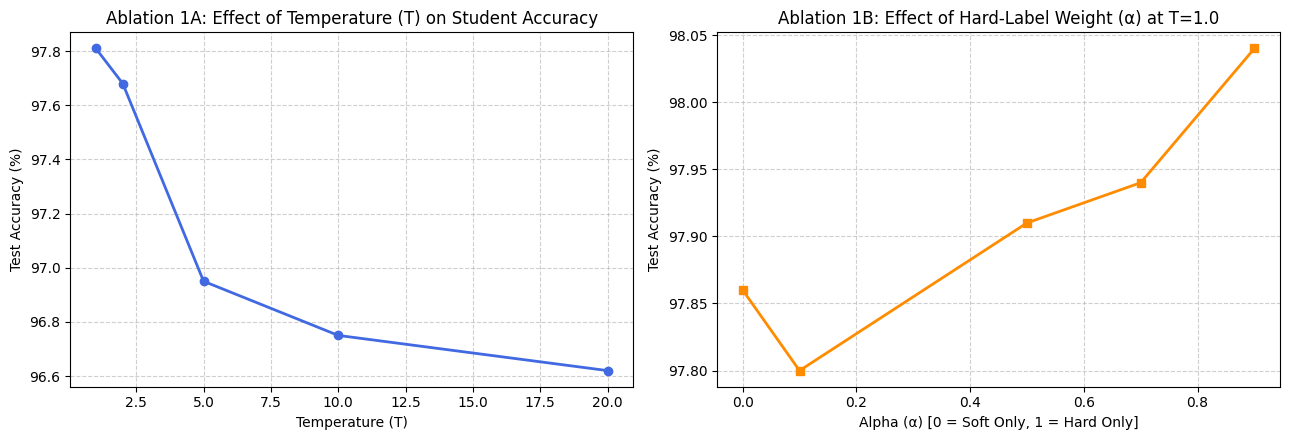

In [7]:
SWEEP_EPOCHS = 4 if DATASET_NAME == "MNIST" else 10

# --- Part A: Temperature Sweep ---
temperatures = [1.0, 2.0, 5.0, 10.0, 20.0]
temp_results = []

print("=== Running Temperature (T) Sweep (Fixed alpha = 0.1) ===")
for T_val in temperatures:
    set_seed(SEED)
    s_model = SmallStudentCNN(IN_CHANNELS, NUM_CLASSES)
    s_model = train_distilled(s_model, teacher_model, train_loader, test_loader,
                              epochs=SWEEP_EPOCHS, lr=1e-3, T=T_val, alpha=0.1, verbose=False)
    acc, err, _ = evaluate(s_model, test_loader)
    temp_results.append({"Temperature (T)": T_val, "Test Accuracy (%)": round(acc, 2), "Test Errors": err})
    print(f"T = {T_val:<4} --> Test Accuracy: {acc:.2f}% ({err} errors)")

temp_df = pd.DataFrame(temp_results)
best_T = temp_df.loc[temp_df["Test Accuracy (%)"].idxmax(), "Temperature (T)"]
print(f"Best Temperature found: T = {best_T}\n")

# --- Part B: Alpha Sweep ---
alphas = [0.0, 0.1, 0.5, 0.7, 0.9]
alpha_results = []

print(f"=== Running Alpha (α) Sweep (Fixed T = {best_T}) ===")
for a_val in alphas:
    set_seed(SEED)
    s_model = SmallStudentCNN(IN_CHANNELS, NUM_CLASSES)
    s_model = train_distilled(s_model, teacher_model, train_loader, test_loader,
                              epochs=SWEEP_EPOCHS, lr=1e-3, T=best_T, alpha=a_val, verbose=False)
    acc, err, _ = evaluate(s_model, test_loader)
    alpha_results.append({"Alpha (α)": a_val, "Test Accuracy (%)": round(acc, 2), "Test Errors": err})
    print(f"Alpha = {a_val:<4} --> Test Accuracy: {acc:.2f}% ({err} errors)")

alpha_df = pd.DataFrame(alpha_results)

# --- Plot Results for Report ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(temp_df["Temperature (T)"], temp_df["Test Accuracy (%)"], marker='o', linewidth=2, color='royalblue')
axes[0].set_title("Ablation 1A: Effect of Temperature (T) on Student Accuracy")
axes[0].set_xlabel("Temperature (T)")
axes[0].set_ylabel("Test Accuracy (%)")
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(alpha_df["Alpha (α)"], alpha_df["Test Accuracy (%)"], marker='s', linewidth=2, color='darkorange')
axes[1].set_title(f"Ablation 1B: Effect of Hard-Label Weight (α) at T={best_T}")
axes[1].set_xlabel("Alpha (α) [0 = Soft Only, 1 = Hard Only]")
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("ablation_temperature_alpha.png", dpi=300)
plt.show()

=== Training Student on Transfer Set WITHOUT Class 3 ===
[NoClass3-HardOnly] Epoch 1/5 | Loss: 0.6115 | Test Acc: 85.78% (1422 errors)
[NoClass3-HardOnly] Epoch 2/5 | Loss: 0.1786 | Test Acc: 87.08% (1292 errors)
[NoClass3-HardOnly] Epoch 3/5 | Loss: 0.1317 | Test Acc: 87.72% (1228 errors)
[NoClass3-HardOnly] Epoch 4/5 | Loss: 0.1107 | Test Acc: 88.16% (1184 errors)
[NoClass3-HardOnly] Epoch 5/5 | Loss: 0.0944 | Test Acc: 88.24% (1176 errors)
[Distill T=10.0, α=0.0] Epoch 1/5 | Loss: 8.5852 | Test Acc: 83.79% (1621 errors)
[Distill T=10.0, α=0.0] Epoch 2/5 | Loss: 2.3507 | Test Acc: 86.42% (1358 errors)
[Distill T=10.0, α=0.0] Epoch 3/5 | Loss: 1.6373 | Test Acc: 86.86% (1314 errors)
[Distill T=10.0, α=0.0] Epoch 4/5 | Loss: 1.3585 | Test Acc: 87.18% (1282 errors)
[Distill T=10.0, α=0.0] Epoch 5/5 | Loss: 1.1767 | Test Acc: 87.52% (1248 errors)

--- Before Bias Adjustment ---
Hard-Target Student (Never saw 3) -> Overall Acc: 88.24% | Class 3 Acc: 0.00% (1010/1010 errors)
Distilled Stud

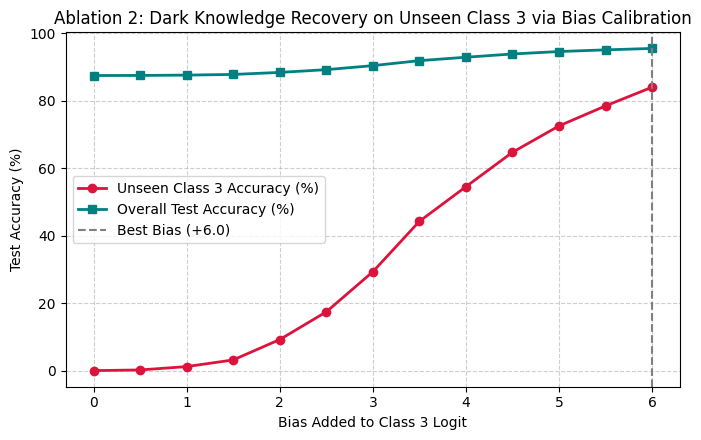

In [8]:
print(f"=== Training Student on Transfer Set WITHOUT Class {HELD_OUT_CLASS} ===")

# 1. Hard-Label Student trained without Class 3 (Fails completely on Class 3)
set_seed(SEED)
student_no3_hard = SmallStudentCNN(IN_CHANNELS, NUM_CLASSES)
student_no3_hard = train_standard(student_no3_hard, train_no_3_loader, test_loader,
                                  epochs=EPOCHS, lr=1e-3, model_name="NoClass3-HardOnly")

# 2. Distilled Student trained without Class 3 using ONLY Teacher Soft Targets (alpha=0.0)
set_seed(SEED)
student_no3_soft = SmallStudentCNN(IN_CHANNELS, NUM_CLASSES)
student_no3_soft = train_distilled(student_no3_soft, teacher_model, train_no_3_loader, test_loader,
                                   epochs=EPOCHS, lr=1e-3, T=10.0, alpha=0.0, verbose=True)

# Evaluate before bias adjustment
hard_overall_acc, _, _ = evaluate(student_no3_hard, test_loader)
hard_c3_acc, hard_c3_err, c3_total = evaluate(student_no3_hard, test_only_3_loader)

soft_overall_acc, soft_overall_err, _ = evaluate(student_no3_soft, test_loader)
soft_c3_acc, soft_c3_err, _ = evaluate(student_no3_soft, test_only_3_loader)

print(f"\n--- Before Bias Adjustment ---")
print(f"Hard-Target Student (Never saw 3) -> Overall Acc: {hard_overall_acc:.2f}% | Class 3 Acc: {hard_c3_acc:.2f}% ({hard_c3_err}/{c3_total} errors)")
print(f"Distilled Student   (Never saw 3) -> Overall Acc: {soft_overall_acc:.2f}% | Class 3 Acc: {soft_c3_acc:.2f}% ({soft_c3_err}/{c3_total} errors)")

# 3. Bias Calibration Sweep on the Held-Out Class (Paper Section 3: adding +3.5 to class 3 bias)
bias_offsets = np.linspace(0.0, 6.0, 13)
bias_sweep_records = []

# Save original bias of the final linear layer
original_bias = copy.deepcopy(student_no3_soft.classifier[2].bias.data)

for offset in bias_offsets:
    with torch.no_grad():
        student_no3_soft.classifier[2].bias.data = copy.deepcopy(original_bias)
        student_no3_soft.classifier[2].bias.data[HELD_OUT_CLASS] += float(offset)

    ov_acc, ov_err, _ = evaluate(student_no3_soft, test_loader)
    c3_acc, c3_err, _ = evaluate(student_no3_soft, test_only_3_loader)
    bias_sweep_records.append({
        "Bias Offset": round(float(offset), 2),
        "Overall Test Acc (%)": round(ov_acc, 2),
        "Overall Errors": ov_err,
        "Held-Out Class 3 Acc (%)": round(c3_acc, 2),
        "Class 3 Errors": c3_err
    })

# Restore original bias
with torch.no_grad():
    student_no3_soft.classifier[2].bias.data = copy.deepcopy(original_bias)

bias_df = pd.DataFrame(bias_sweep_records)
best_row = bias_df.loc[bias_df["Overall Test Acc (%)"].idxmax()]

print("\n=== HELD-OUT CLASS (DARK KNOWLEDGE) BIAS CALIBRATION TABLE ===")
print(bias_df.to_string(index=False))
print(f"\nOptimal Bias Offset (+{best_row['Bias Offset']}): Overall Acc = {best_row['Overall Test Acc (%)']}% | Unseen Class 3 Acc = {best_row['Held-Out Class 3 Acc (%)']}%!")

# Plot Dark Knowledge Bias Calibration Curve
plt.figure(figsize=(7, 4.5))
plt.plot(bias_df["Bias Offset"], bias_df["Held-Out Class 3 Acc (%)"], marker='o', label="Unseen Class 3 Accuracy (%)", linewidth=2, color='crimson')
plt.plot(bias_df["Bias Offset"], bias_df["Overall Test Acc (%)"], marker='s', label="Overall Test Accuracy (%)", linewidth=2, color='teal')
plt.axvline(best_row["Bias Offset"], color='gray', linestyle='--', label=f"Best Bias (+{best_row['Bias Offset']})")
plt.title("Ablation 2: Dark Knowledge Recovery on Unseen Class 3 via Bias Calibration")
plt.xlabel("Bias Added to Class 3 Logit")
plt.ylabel("Test Accuracy (%)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("ablation_dark_knowledge_class3.png", dpi=300)
plt.show()